=== HASIL EVALUASI MODEL XGBOOST ===
RMSE : $47,385.26
R²   : 0.8287


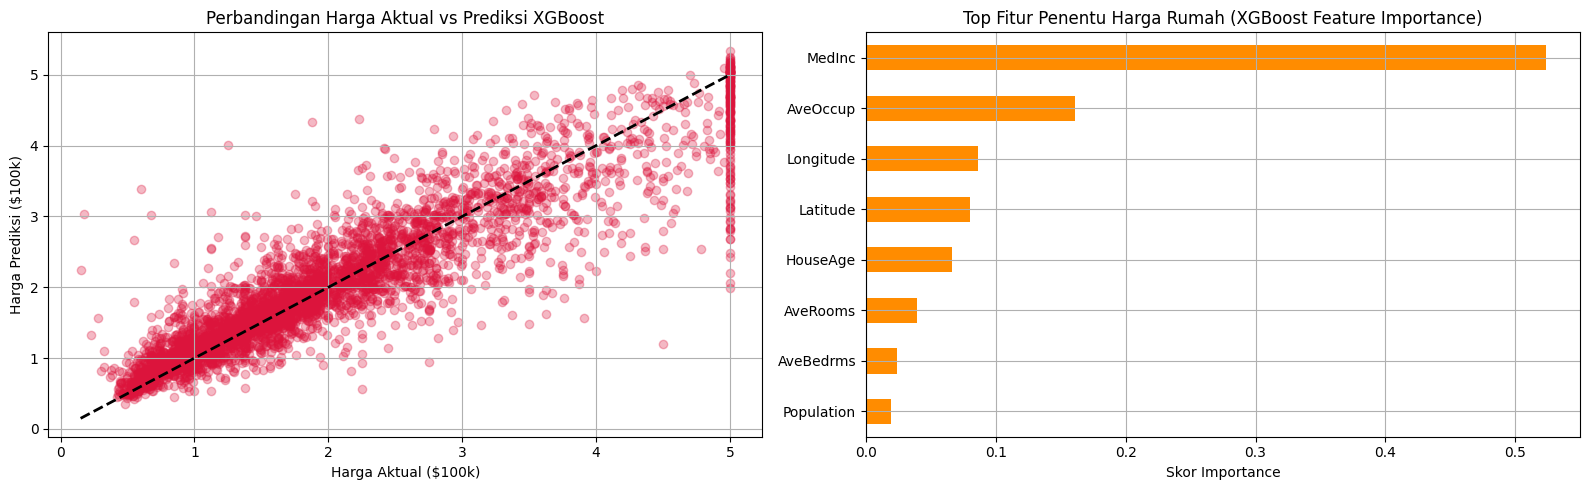

In [3]:
# XGBoost
# Membangun pohon secara horizontal (seimbang tingkat demi tingkat). XGBoost akan memeriksa seluruh cabang di satu kedalaman sebelum turun ke level berikutnya.
# Efek: Lebih stabil dan tidak gampang overfitting, tapi butuh waktu komputasi lebih lama.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

# 1. LOAD DATASET (California Housing)
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# 2. PEMBERSIHAN DATA & PREPROCESSING
# A. Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']  # Nilai rumah dalam ratusan ribu $

# B. Train-Test Split (80:20)
# Catatan: XGBoost tidak wajib membutuhkan StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. TRAINING MODEL XGBOOST
model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)
model.fit(X_train, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL XGBOOST ===")
print(f"RMSE : ${rmse * 100000:,.2f}")
print(f"R²   : {r2:.4f}")

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Visualisasi 1: Nilai Aktual vs Prediksi
axes[0].scatter(y_test, y_pred, alpha=0.3, color='crimson')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
axes[0].set_xlabel("Harga Aktual ($100k)")
axes[0].set_ylabel("Harga Prediksi ($100k)")
axes[0].set_title("Perbandingan Harga Aktual vs Prediksi XGBoost")
axes[0].grid(True)

# Visualisasi 2: Feature Importance
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title("Top Fitur Penentu Harga Rumah (XGBoost Feature Importance)")
axes[1].set_xlabel("Skor Importance")
axes[1].grid(True)

plt.tight_layout()
plt.show()

=== HASIL EVALUASI MODEL LIGHTGBM ===
Akurasi Model : 99.64%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       153
           1       0.99      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



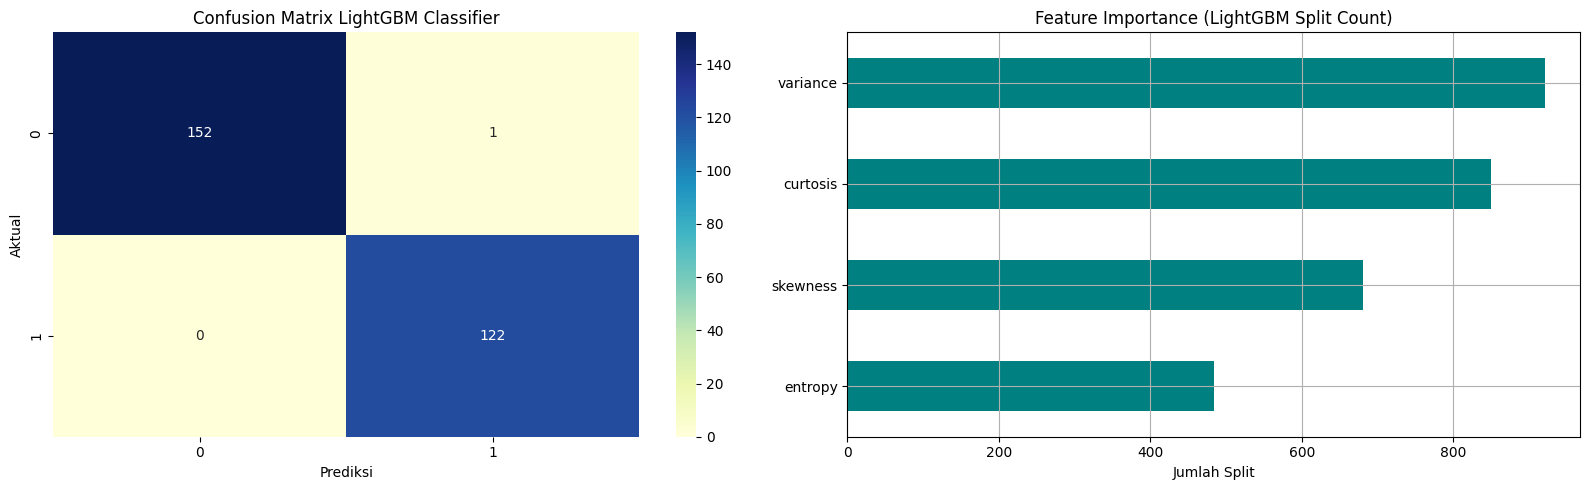

In [4]:
# LightGBM
# Membangun pohon secara vertikal (fokus pada daun yang memiliki kesalahan/loss terbesar).
# Efek: Menemukan pola dengan sangat cepat dan akurasi tinggi, tapi bisa rentan overfitting pada dataset kecil jika max_depth atau num_leaves tidak dibatasi.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import lightgbm as lgb

# 1. LOAD DATASET (Bank Marketing / Fraud Dataset)
url = "https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/main/data/bank-full.csv" # Alternatif publik
# Menggunakan dataset Bank Marketing (45,000+ baris data)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/BankMarketing.csv" if False else \
      "https://raw.githubusercontent.com/jbrownlee/Datasets/master/banknote_authentication.csv"

# Dataset Banknote Authentication (Sangat bersih untuk benchmark kecepatan)
df = pd.read_csv(url, header=None)
df.columns = ['variance', 'skewness', 'curtosis', 'entropy', 'class']

# 2. PEMBERSIHAN DATA & PREPROCESSING
X = df.drop(columns=['class'])
y = df['class']

# Train-Test Split (80:20)
# LightGBM TIDAK membutuhkan StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. TRAINING MODEL LIGHTGBM
# Inisialisasi model LightGBM Classifier
model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)
model.fit(X_train, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL LIGHTGBM ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Visualisasi 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    ax=axes[0]
)
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
axes[0].set_title("Confusion Matrix LightGBM Classifier")

# Visualisasi 2: Feature Importance LightGBM
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title("Feature Importance (LightGBM Split Count)")
axes[1].set_xlabel("Jumlah Split")
axes[1].grid(True)

plt.tight_layout()
plt.show()